---
date: "2026-09-21"
date-modified: last-modified
format:
  html:
    toc: true
---


# Linear Functionals and Dual Spaces

## 1\. Linear Maps

::: {#def-linear-map}
## Linear Map

Let $V$ and $W$ be [vector spaces](vector-spaces.ipynb) over the same [field](field.ipynb) $K$. A function $f: V \to W$ is called a **linear map** (or **linear transformation**) if it satisfies:

1. **Preserves addition:** $f(v_1 + v_2) = f(v_1) + f(v_2)$ for all $v_1, v_2 \in V$.
2. **Preserves scalar multiplication:** $f(\alpha v) = \alpha f(v)$ for all $\alpha \in K$, $v \in V$.
:::

---

## 2\. Linear Functionals

The special case where the codomain is the field $K$ itself is fundamental.

::: {#def-linear-functional}
## Linear Functional

A **linear functional** on $V$ is a linear map $f: V \to K$.

Note that $K$ is itself a $1$-dimensional vector space over $K$.
:::

::: {.callout-note}
## Linear Functionals = Homogeneous Degree-1 Expressions
If $\{b_1, \dots, b_n\}$ is a [basis](linear-independence-basis-dimension.ipynb#def-basis) for $V$ and $v = v_1 b_1 + \cdots + v_n b_n$, then every linear functional $f$ takes the form:

$$f(v) = c_1 v_1 + c_2 v_2 + \cdots + c_n v_n$$

where $c_i = f(b_i) \in K$. This is a **degree-1 homogeneous** expression in the coordinates.
:::


## 3\. Examples of Linear Functionals

### 3\.1\. Projection

For $K^n$ with the standard basis, the **projection onto the $j$-th component** is:

$$p_j(x_1, \dots, x_n) = x_j$$

This is linear because it is the degree-1 expression $0 \cdot x_1 + \cdots + 1 \cdot x_j + \cdots + 0 \cdot x_n$.

---

### 3\.2\. Inner Product with a Fixed Vector

Fix $a = (a_1, \dots, a_n) \in \mathbb{R}^n$. Define:

$$f(x) = \langle a, x \rangle = a_1 x_1 + \cdots + a_n x_n$$

This is linear: it is a degree-1 expression $\sum a_i x_i$, which preserves sums and scalar multiples.

---

### 3\.3\. Evaluation at a Point

Let $\mathcal{F}$ be the vector space of all functions $\mathbb{R} \to \mathbb{R}$. For a fixed $t \in \mathbb{R}$, define:

$$L(f) = f(t)$$

$L$ is a linear functional on $\mathcal{F}$, since $(f+g)(t) = f(t) + g(t)$ and $(\alpha f)(t) = \alpha f(t)$.

This applies equally to finite-dimensional subspaces, e.g. polynomials of degree $\le n$.

---

### 3\.4\. Integration

Let $\mathcal{I}$ be the space of integrable functions on $[a, b]$. Define:

$$I(f) = \int_a^b f(x)\, dx$$

$I$ is a linear functional, since $\int(f+g) = \int f + \int g$ and $\int(\alpha f) = \alpha \int f$.

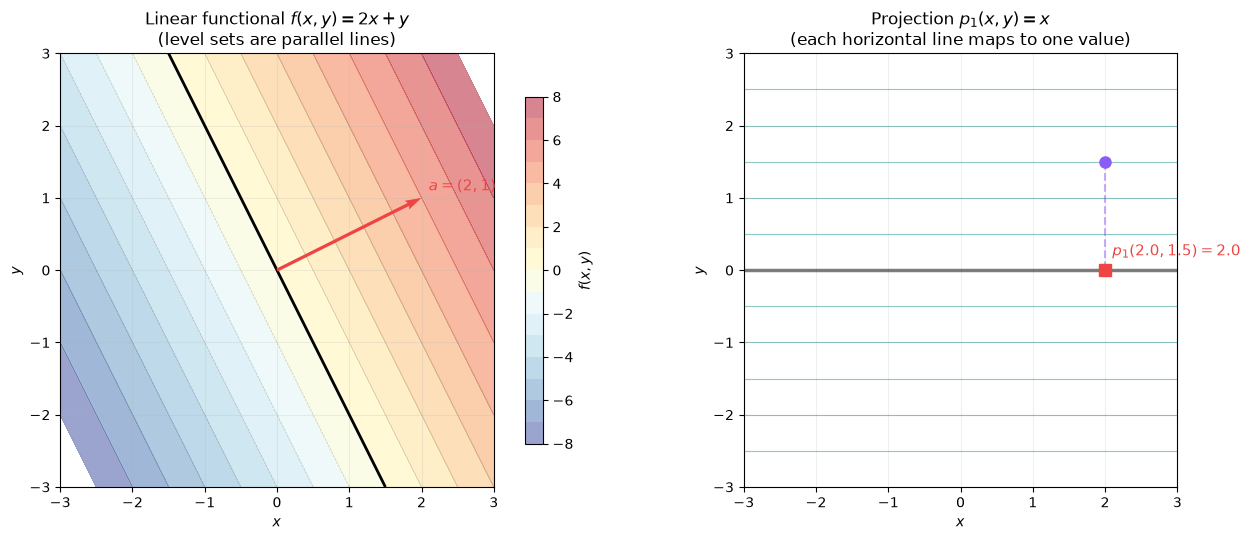

In [1]:

import numpy as np
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# --- Panel 1: Level sets of a linear functional f(x,y) = 2x + y ---
ax = axes[0]
xx, yy = np.meshgrid(np.linspace(-3, 3, 300), np.linspace(-3, 3, 300))
zz = 2*xx + yy
levels = np.arange(-8, 9, 1)
cs = ax.contourf(xx, yy, zz, levels=levels, cmap='RdYlBu_r', alpha=0.5)
ax.contour(xx, yy, zz, levels=levels, colors='gray', linewidths=0.5, alpha=0.4)
# highlight f=0 level
ax.contour(xx, yy, zz, levels=[0], colors='black', linewidths=2)
plt.colorbar(cs, ax=ax, label='$f(x,y)$', shrink=0.8)
# gradient direction
ax.quiver(0, 0, 2, 1, angles='xy', scale_units='xy', scale=1,
          color='#ef4444', linewidth=2, zorder=5)
ax.text(2.1, 1.1, '$a = (2,1)$', fontsize=11, color='#ef4444')
ax.set_xlim(-3, 3); ax.set_ylim(-3, 3)
ax.set_aspect('equal'); ax.grid(True, alpha=0.2)
ax.set_title('Linear functional $f(x,y) = 2x + y$\n(level sets are parallel lines)',
             fontsize=12)
ax.set_xlabel('$x$'); ax.set_ylabel('$y$')

# --- Panel 2: Projection p₁ ---
ax = axes[1]
for y_val in np.linspace(-2.5, 2.5, 11):
    color = plt.cm.viridis(0.5) if abs(y_val) > 0.01 else 'black'
    lw = 2.5 if abs(y_val) < 0.01 else 0.8
    ax.axhline(y=y_val, color=color, linewidth=lw, alpha=0.5)

# Show projection of a point
pt = np.array([2.0, 1.5])
ax.plot(*pt, 'o', color='#8b5cf6', markersize=8, zorder=5)
ax.plot([pt[0], pt[0]], [pt[1], 0], '--', color='#8b5cf6', alpha=0.5)
ax.plot(pt[0], 0, 's', color='#ef4444', markersize=8, zorder=5)
ax.annotate(f'$p_1({pt[0]},{pt[1]}) = {pt[0]}$',
            (pt[0]+0.1, 0.2), fontsize=11, color='#ef4444')

ax.set_xlim(-3, 3); ax.set_ylim(-3, 3)
ax.set_aspect('equal'); ax.grid(True, alpha=0.2)
ax.set_title('Projection $p_1(x,y) = x$\n(each horizontal line maps to one value)',
             fontsize=12)
ax.set_xlabel('$x$'); ax.set_ylabel('$y$')

plt.tight_layout()
plt.show()


## 4\. Characterisation of Linear Functionals

::: {#prp-functional-characterisation}
## Every Linear Functional is a Degree-1 Expression

Let $V$ be a finite-dimensional space with basis $\{b_1, \dots, b_n\}$. If $f: V \to K$ is a linear functional, then for every $v = v_1 b_1 + \cdots + v_n b_n \in V$:

$$f(v) = \sum_{i=1}^n f(b_i)\, v_i$$

That is, $f$ is completely determined by its values on the basis vectors, and these values serve as the coefficients of a degree-1 homogeneous expression.
:::

::: {.callout-tip collapse="true"}
## Proof of @prp-functional-characterisation

Set $c_i = f(b_i)$ for each $i$. For any $v = \sum_i v_i b_i$:

$$f(v) = f\!\left(\sum_{i=1}^n v_i b_i\right) = \sum_{i=1}^n f(v_i b_i) = \sum_{i=1}^n v_i\, f(b_i) = \sum_{i=1}^n c_i\, v_i$$

The first equality uses preservation of addition (property 1, extended by induction), the second uses preservation of scalar multiplication (property 2).

$\blacksquare$
:::

::: {.callout-note}
## Key Insight
A linear functional on a finite-dimensional space is fully determined by its values on a basis. The coefficients $c_i = f(b_i)$ depend on the choice of basis — different bases yield different coefficients for the same functional.
:::


## 5\. The Dual Space

::: {#def-dual-space}
## Dual Space

The **dual space** of $V$, denoted $V^*$, is the set of all linear functionals on $V$:

$$V^* = \{f: V \to K \mid f \text{ is linear}\}$$

$V^*$ is itself a vector space over $K$ with pointwise operations:

$$
\begin{aligned}
(f + g)(x) &= f(x) + g(x) \\
(\alpha f)(x) &= \alpha\, f(x)
\end{aligned}
$$
:::

::: {.callout-tip collapse="true"}
## $V^*$ is a Vector Space

If $f$ and $g$ are linear, then $f + g$ is linear:

$$(f+g)(x+x') = f(x+x') + g(x+x') = f(x) + f(x') + g(x) + g(x') = (f+g)(x) + (f+g)(x')$$

Similarly, $\alpha f$ is linear: $(\alpha f)(\beta x) = \alpha f(\beta x) = \alpha \beta f(x) = \beta (\alpha f)(x)$.

The remaining vector space axioms are inherited from pointwise operations.

$\blacksquare$
:::


## 6\. The Dual Basis

::: {#def-dual-basis}
## Dual Basis

Let $\{v_1, \dots, v_n\}$ be a basis for $V$. The **dual basis** $\{v^1, \dots, v^n\} \subset V^*$ is defined by:

$$v^i(v_j) = \delta_{ij} = \begin{cases} 1 & \text{if } i = j \\ 0 & \text{if } i \neq j \end{cases}$$

In general, $v^i$ acts on an arbitrary vector $v = \sum_j \alpha_j v_j$ by:

$$v^i(v) = v^i\!\left(\sum_j \alpha_j v_j\right) = \sum_j \alpha_j\, v^i(v_j) = \alpha_i$$

That is, $v^i$ **extracts the $i$-th coordinate** of $v$ with respect to the basis $\{v_1, \dots, v_n\}$.
:::

---

::: {#thm-dual-basis-is-basis}
## The Dual Basis is a Basis for $V^*$

The dual basis $\{v^1, \dots, v^n\}$ is a basis for $V^*$. In particular:

$$\dim(V^*) = \dim(V) = n$$
:::

::: {.callout-tip collapse="true"}
## Proof of @thm-dual-basis-is-basis

**Linear independence.** Suppose $\sum_i \alpha_i v^i = 0$ (the zero functional). Evaluate both sides on $v_j$:

$$0 = \left(\sum_i \alpha_i v^i\right)(v_j) = \sum_i \alpha_i\, v^i(v_j) = \alpha_j$$

since $v^i(v_j) = \delta_{ij}$. This holds for every $j$, so all $\alpha_j = 0$.

**Spanning.** Let $f \in V^*$ be any linear functional. We claim:

$$f = \sum_{j=1}^n f(v_j)\, v^j$$

Both sides are linear functionals, so it suffices to check they agree on each basis vector $v_k$. Evaluating the right side on $v_k$:

$$\left(\sum_j f(v_j)\, v^j\right)(v_k) = \sum_j f(v_j)\, v^j(v_k) = f(v_k) \cdot 1 = f(v_k)$$

which equals the left side. Since they agree on a basis, they are equal everywhere.

$\blacksquare$
:::

::: {.callout-note}
## Index Convention
It is conventional to write the dual basis with **upper indices** ($v^i$) and the original basis with **lower indices** ($v_j$). This notation anticipates the Einstein summation convention used in tensor analysis and differential geometry, where repeated upper-lower index pairs are implicitly summed.
:::

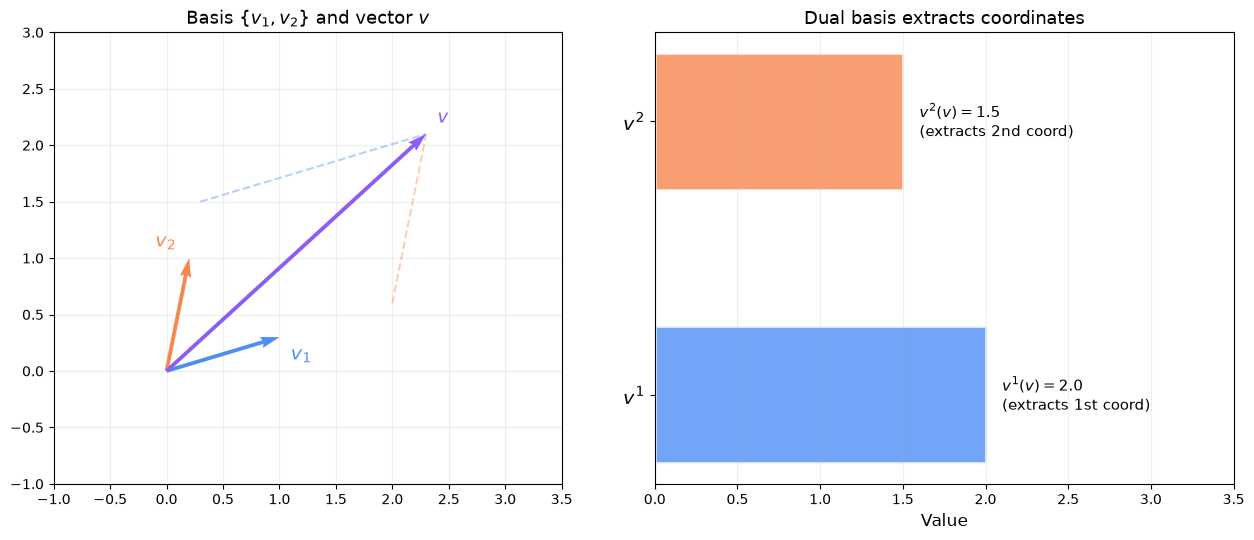

In [2]:

import numpy as np
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

# A non-orthogonal basis in R²
b1 = np.array([1.0, 0.3])
b2 = np.array([0.2, 1.0])
t = np.linspace(-3, 3, 100)

# --- Panel 1: Basis vectors ---
ax = axes[0]
ax.quiver(0, 0, *b1, angles='xy', scale_units='xy', scale=1,
          color='#4f8df5', linewidth=2.5, zorder=5)
ax.quiver(0, 0, *b2, angles='xy', scale_units='xy', scale=1,
          color='#f5874f', linewidth=2.5, zorder=5)
ax.text(b1[0]+0.1, b1[1]-0.2, '$v_1$', fontsize=14, color='#4f8df5',
        fontweight='bold')
ax.text(b2[0]-0.3, b2[1]+0.1, '$v_2$', fontsize=14, color='#f5874f',
        fontweight='bold')

# Show a vector and its coordinates
v = 2.0 * b1 + 1.5 * b2
ax.quiver(0, 0, *v, angles='xy', scale_units='xy', scale=1,
          color='#8b5cf6', linewidth=2.5, zorder=5)
ax.text(v[0]+0.1, v[1]+0.1, '$v$', fontsize=13, color='#8b5cf6')
# parallelogram
ax.plot([2*b1[0], v[0]], [2*b1[1], v[1]], '--', color='#f5874f', alpha=0.4)
ax.plot([1.5*b2[0], v[0]], [1.5*b2[1], v[1]], '--', color='#4f8df5', alpha=0.4)

ax.set_xlim(-1, 3.5); ax.set_ylim(-1, 3)
ax.set_aspect('equal'); ax.grid(True, alpha=0.2)
ax.set_title('Basis $\\{v_1, v_2\\}$ and vector $v$', fontsize=13)

# --- Panel 2: Dual basis action ---
ax = axes[1]
coords = [2.0, 1.5]
labels = ['$v^1(v) = 2.0$\n(extracts 1st coord)',
          '$v^2(v) = 1.5$\n(extracts 2nd coord)']
colors_bar = ['#4f8df5', '#f5874f']

bars = ax.barh([0, 1], coords, color=colors_bar, height=0.5, alpha=0.8,
               edgecolor='white', linewidth=2)
for i, (c, lbl) in enumerate(zip(coords, labels)):
    ax.text(c + 0.1, i, lbl, va='center', fontsize=11)
ax.set_yticks([0, 1])
ax.set_yticklabels(['$v^1$', '$v^2$'], fontsize=14)
ax.set_xlim(0, 3.5)
ax.set_title('Dual basis extracts coordinates', fontsize=13)
ax.set_xlabel('Value', fontsize=12)
ax.grid(True, axis='x', alpha=0.2)

plt.tight_layout()
plt.show()


## 7\. Application: Quadrature for Polynomials

::: {#prp-quadrature}
## Exact Quadrature from $n$ Points

Let $x_1, \dots, x_n$ be $n$ distinct points in $[a, b]$. Then there exist constants $c_1, \dots, c_n \in \mathbb{R}$ (independent of $P$) such that for every polynomial $P$ of degree $< n$:

$$\int_a^b P(x)\, dx = c_1\, P(x_1) + c_2\, P(x_2) + \cdots + c_n\, P(x_n)$$
:::

::: {.callout-tip collapse="true"}
## Proof of @prp-quadrature

Let $\mathcal{P}_{n-1}$ be the space of polynomials of degree $< n$. This is an $n$-dimensional vector space with basis $\{1, x, x^2, \dots, x^{n-1}\}$.

**Integration is a linear functional.** The map $I(P) = \int_a^b P(x)\, dx$ is a linear functional on $\mathcal{P}_{n-1}$, hence $I \in \mathcal{P}_{n-1}^*$.

**Evaluations form a basis for $\mathcal{P}_{n-1}^*$.** 

Define $\beta_i \in \mathcal{P}_{n-1}^*$ by $\beta_i(P) = P(x_i)$. Each $\beta_i$ is a linear functional ($\beta_i(P+Q) = (P+Q)(x_i) = P(x_i) + Q(x_i)$, etc.).

**$\{\beta_1, \dots, \beta_n\}$ is linearly independent.** 

Suppose $\sum_i \alpha_i \beta_i = 0$. Define the polynomial:

$$Q_j(x) = \prod_{i \neq j} (x - x_i)$$

This has degree $n - 1$ and satisfies $Q_j(x_i) = 0$ for $i \neq j$, while $Q_j(x_j) \neq 0$. Evaluating $\sum_i \alpha_i \beta_i$ on $Q_j$:

$$0 = \sum_i \alpha_i\, Q_j(x_i) = \alpha_j\, Q_j(x_j)$$

Since $Q_j(x_j) \neq 0$, we get $\alpha_j = 0$. This holds for all $j$, proving linear independence.

**Conclusion.** Since $\dim(\mathcal{P}_{n-1}^*) = n$ and $\{\beta_1, \dots, \beta_n\}$ is a linearly independent set of $n$ elements, it is a [basis](linear-independence-basis-dimension.ipynb#cor-independent-full-size). Express $I$ in this basis:

$$I = \sum_i c_i \beta_i$$

Applying both sides to any $P \in \mathcal{P}_{n-1}$:

$$\int_a^b P(x)\, dx = \sum_i c_i\, P(x_i)$$

$\blacksquare$
:::

::: {.callout-note}
## Why Linear Dependence on Values?
A polynomial of degree $< n$ is determined by $n$ coefficients, so knowing its values at $n$ distinct points determines the polynomial completely (and hence its integral). The non-obvious fact is that the integral depends **linearly** on these values — this follows from the linear-algebraic structure of $\mathcal{P}_{n-1}^*$.
:::

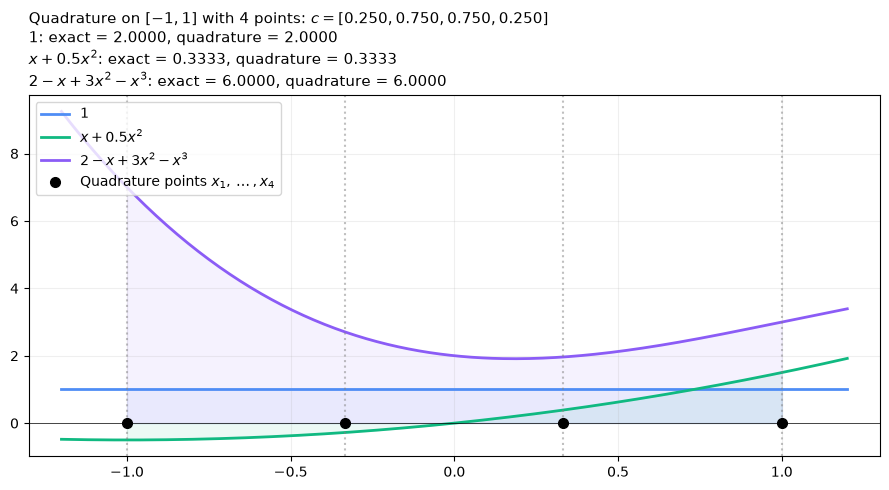

In [3]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad

# Quadrature for degree < 4 polynomials using 4 points on [-1, 1]
a, b = -1, 1
n = 4
# Choose n distinct points (e.g., equally spaced)
x_pts = np.linspace(a, b, n)

# Build the Vandermonde system to find weights c_i
# We need: int_a^b x^k dx = sum_i c_i * x_i^k, for k = 0,...,n-1
A_mat = np.vander(x_pts, n, increasing=True).T
rhs = np.array([(b**(k+1) - a**(k+1)) / (k+1) for k in range(n)])
c_weights = np.linalg.solve(A_mat, rhs)

# Test on several polynomials
fig, ax = plt.subplots(figsize=(9, 5))
x_fine = np.linspace(a - 0.2, b + 0.2, 300)

test_polys = [
    (lambda x: 1 + 0*x, '$1$'),
    (lambda x: x + 0.5*x**2, '$x + 0.5x^2$'),
    (lambda x: 2 - x + 3*x**2 - x**3, '$2 - x + 3x^2 - x^3$'),
]
colors = ['#4f8df5', '#10b981', '#8b5cf6']

results = []
for (P, label), col in zip(test_polys, colors):
    exact, _ = quad(P, a, b)
    approx = sum(c * P(xi) for c, xi in zip(c_weights, x_pts))
    results.append((label, exact, approx))
    ax.plot(x_fine, P(x_fine), color=col, linewidth=2, label=label)
    ax.fill_between(np.linspace(a, b, 200), 0, P(np.linspace(a, b, 200)),
                    color=col, alpha=0.08)

# Mark the quadrature points
for xi in x_pts:
    ax.axvline(x=xi, color='gray', linestyle=':', alpha=0.5)
ax.plot(x_pts, np.zeros_like(x_pts), 'ko', markersize=7, zorder=5,
        label=f'Quadrature points $x_1,\\dots,x_{n}$')

ax.set_xlim(a - 0.3, b + 0.3)
ax.axhline(y=0, color='black', linewidth=0.5)
ax.legend(fontsize=10, loc='upper left')
ax.grid(True, alpha=0.2)

title_lines = [f'Quadrature on $[-1,1]$ with {n} points: '
               f'$c = [{', '.join(f'{w:.3f}' for w in c_weights)}]$']
for label, exact, approx in results:
    title_lines.append(f'{label}: exact = {exact:.4f}, quadrature = {approx:.4f}')
ax.set_title('\n'.join(title_lines), fontsize=11, loc='left')

plt.tight_layout()
plt.show()


## 8\. The Double Dual and the Natural Isomorphism

### 8\.1\. The Double Dual

::: {#def-double-dual}
## Double Dual

The **double dual** (or **bidual**) of $V$ is:

$$V^{**} = (V^*)^*$$

the space of all linear functionals on $V^*$. Since $\dim(V^*) = n$, we have $\dim(V^{**}) = n$ as well.
:::

Elements of $V^{**}$ are "functionals on functionals" — each $\alpha \in V^{**}$ takes a linear functional $f \in V^*$ and produces a scalar $\alpha(f) \in K$.

---

### 8\.2\. The Natural Isomorphism $V \cong V^{**}$

Any two $n$-dimensional spaces are isomorphic, so $V \cong V^{**}$ trivially. The remarkable fact is that there exists a **natural** (canonical) isomorphism — one that does not depend on any choice of basis.

::: {#thm-natural-iso}
## Natural Isomorphism $V \cong V^{**}$

Define $\iota: V \to V^{**}$ by:

$$\iota(v)(f) = f(v) \qquad \text{for all } f \in V^*$$

Then $\iota$ is a linear isomorphism. No basis is used in this definition.
:::

::: {.callout-tip collapse="true"}
## Proof of @thm-natural-iso

**$\iota(v)$ is well-defined and linear.** For each $v \in V$, $\iota(v)$ must be a linear functional on $V^*$. We check:

- $\iota(v)(f + g) = (f+g)(v) = f(v) + g(v) = \iota(v)(f) + \iota(v)(g)$
- $\iota(v)(\alpha f) = (\alpha f)(v) = \alpha f(v) = \alpha\, \iota(v)(f)$

**$\iota$ is linear.** For all $f \in V^*$:

- $\iota(v + w)(f) = f(v + w) = f(v) + f(w) = \iota(v)(f) + \iota(w)(f)$, so $\iota(v+w) = \iota(v) + \iota(w)$.
- $\iota(cv)(f) = f(cv) = c\,f(v) = c\,\iota(v)(f)$, so $\iota(cv) = c\,\iota(v)$.

Both use the fact that $f \in V^*$ is itself linear.

**$\iota$ is injective.** Suppose $\iota(v) = \iota(w)$, i.e., $f(v) = f(w)$ for all $f \in V^*$. Then $f(v - w) = 0$ for all $f \in V^*$. If $v - w \neq 0$, extend $\{v - w\}$ to a basis and take the corresponding dual basis element — it would give a non-zero value on $v - w$, a contradiction. So $v = w$.

**$\iota$ is surjective.** Since $\iota$ is a linear injection between spaces of the same dimension $n$, it is automatically surjective. (A linearly independent image of a basis in $V$ gives $n$ independent vectors in the $n$-dimensional space $V^{**}$, which must therefore span it.)

$\blacksquare$
:::

::: {.callout-warning}
## Natural vs Non-Natural Isomorphism

| | $V \cong V^*$ | $V \cong V^{**}$ |
|---|---|---|
| **Exists?** | Yes (same dimension) | Yes |
| **Requires basis?** | Yes — depends on choice of basis | **No** — the map $\iota(v)(f) = f(v)$ uses no basis |
| **Canonical?** | No — different bases give different isomorphisms | **Yes** — there is one distinguished isomorphism |

The isomorphism $V \cong V^*$ requires choosing a basis (or an inner product). The isomorphism $V \cong V^{**}$ is intrinsic to the structure of $V$ itself — it is defined purely from the evaluation pairing between vectors and functionals.
:::